# Will this student get placed?

Predict `placed` (1 = offer through the placement cell) for a new list of registered students. Scored by F1 for `placed = 1`.

Sections: 1 Summary, 2 Dataset, 3 EDA, 4 Leak, 5 Models, 6 Results, 7 Explainable AI, 8 Gate, 9 Limits and scaling, Appendix.

A written report with the same results is included as `report.pdf`.

In [1]:
# Setup: imports, saved artefacts, plotting style and every helper used below.
# Nothing in this notebook refits a model: results come from reports/, model/model.joblib and data/train.csv.
import json
import warnings

warnings.filterwarnings("ignore")

from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from matplotlib.patches import FancyBboxPatch, Rectangle
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

import placement_lib as pl

%matplotlib inline

FIGDIR = Path("docs/figures")
FIGDIR.mkdir(parents=True, exist_ok=True)
GREY, ACCENT, LIGHT, GOLD = "#9E9E9E", "#1F4E79", "#D9D9D9", "#E0A100"
WIDTH = 12  # every figure is 12 inches wide
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 11,
                     "ytick.labelsize": 11, "legend.fontsize": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "font.family": "DejaVu Sans", "figure.dpi": 80})
TRACKS = ("clean", "status")

# ----------------------------------------------------------------------------- saved artefacts
df = pd.read_csv("data/train.csv", dtype={"student_id": str})
y = df.placed.to_numpy()
X = df.drop(columns="placed")
FEATS = [c for c in df.columns if c not in ("student_id", "placed")]
NUMS = [c for c in FEATS if c != "department"]
cv = pd.read_csv("reports/cv_results.csv")
sim, sweep, runs = (pd.read_csv(f"reports/{n}.csv") for n in ("gate_sim", "gate_sweep", "gate_runs"))
checks = pd.read_csv("reports/feature_checks.csv").set_index("track")
rob = pd.read_csv("reports/robustness.csv").groupby(["track", "blank_frac"]).f1.mean()
grids = {t: pd.read_csv(f"reports/lr_grid_{t}.csv") for t in TRACKS}
bundle = joblib.load("model/model.joblib")
oof = {(t, c): np.load(f"reports/oof_{t}_{c}.npy").mean(axis=0) for t in TRACKS for c in cv.candidate.unique()}
thr = {t: float(bundle[t]["threshold"]) for t in TRACKS}
GATE_THR, GATE_MIN = float(bundle["gate"]["threshold"]), int(bundle["gate"]["min_rows"])
NFOLDS = pl.N_SPLITS * pl.N_REPEATS
SEL_MARGIN, SEL_WINS = 0.01, 15  # selection rule in train.py
row = lambda t, c: cv[(cv.track == t) & (cv.candidate == c)].iloc[0]

MAIN = ["A", "LGBM", "XGB", "C1"]
NAME = {"A": "LogReg", "LGBM": "LightGBM", "XGB": "XGBoost", "C1": "Blend LR+LGBM",
        "C2": "Blend: LR + XGBoost", "C3": "Blend: LR + LightGBM + XGBoost", "ST": "Stacking (LR meta-model)"}
SCEN = {"a_as_is": "intact", "b_shuffled": "shuffled", "c_blank": "blank", "d_half_blank": "half blank"}
f3 = lambda v: f"{v:.3f}"
pct = lambda v: f"{100 * v:.1f}%"
pm = lambda m, s: f"{m:.3f} ± {s:.3f}"


def show(t: pd.DataFrame, collapsed: str | None = None) -> None:
    """Small table, no index, 3 decimals."""
    sty = (t.style.hide(axis="index").format(precision=3)
           .set_properties(**{"text-align": "left"})
           .set_table_styles([{"selector": "th", "props": "text-align: left"}]))
    if collapsed:
        display(HTML(f"<details><summary><b>{collapsed}</b></summary>{sty.to_html()}</details>"))
    else:
        display(sty)


def save(fig: plt.Figure, name: str) -> None:
    fig.savefig(FIGDIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def pr_at(t: str, c: str) -> tuple[float, float]:
    """Precision and recall of the OOF predictions at the model's chosen threshold."""
    pred = (oof[(t, c)] >= row(t, c).best_threshold).astype(int)
    return precision_score(y, pred), recall_score(y, pred)


# ----------------------------------------------------------------------------- diagrams
def _box(ax, x, y0, text, w, h, fc="white", ec=ACCENT, color="black"):
    ax.add_patch(FancyBboxPatch((x - w / 2, y0 - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.12",
                                fc=fc, ec=ec, lw=1.4))
    ax.text(x, y0, text, ha="center", va="center", fontsize=11, color=color)


def _arrow(ax, a, b, w, label=None):
    ax.annotate("", xy=(b[0] - w / 2, b[1]), xytext=(a[0] + w / 2, a[1]),
                arrowprops=dict(arrowstyle="-|>", color="#555555", lw=1.2, mutation_scale=14))
    if label:
        ax.text((a[0] + b[0]) / 2 - 0.2, (a[1] + b[1]) / 2 + (0.25 if b[1] > a[1] else -0.35), label, ha="right",
                fontsize=11, color="#555555")


def fig_workflow() -> None:
    W, H, dx = 1.5, 0.82, 1.7
    top, mid, bot = 2.05, 1.25, 0.45
    C, S = "#E8EEF5", "#F2F2F2"
    win = {t: f"{'LogReg' if bundle[t]['name'] == 'A' else bundle[t]['name']} wins\nF1 {row(t, bundle[t]['name']).nested_f1_mean:.3f}"
           for t in TRACKS}
    nodes = {
        "data": (0, mid, f"train.csv\n{len(df):,} rows", "white"), "chk": (1, mid, "data\nchecks", "white"),
        "leak": (2, mid, "leakage\ncheck", "white"),
        "ct": (3, top, f"clean track\n{len(pl.NUM_COLS) + 1} features", C), "st": (3, bot, f"status track\n{len(pl.NUM_COLS) + 2} features", S),
        "cm": (4, top, f"4 models\n{pl.N_SPLITS}×{pl.N_REPEATS} CV", C), "sm": (4, bot, f"4 models\n{pl.N_SPLITS}×{pl.N_REPEATS} CV", S),
        "ch": (5, top, f"threshold\ntuned: {thr['clean']:.2f}", C), "sh": (5, bot, f"threshold\ntuned: {thr['status']:.2f}", S),
        "cw": (6, top, win["clean"], C), "sw": (6, bot, win["status"], S),
        "gate": (7, mid, f"gate\nAUC > {GATE_THR:.2f}", "#FFF4DC"), "pred": (8, mid, "predict.py", "white"),
    }
    fig, ax = plt.subplots(figsize=(WIDTH, 2.9))
    pos = {k: (c * dx, yy) for k, (c, yy, _, _) in nodes.items()}
    for k, (c, yy, text, fc) in nodes.items():
        _box(ax, c * dx, yy, text, W, H, fc=fc, ec=GOLD if k == "gate" else ACCENT)
    for a, b in [("data", "chk"), ("chk", "leak"), ("leak", "ct"), ("leak", "st"), ("ct", "cm"), ("cm", "ch"),
                 ("ch", "cw"), ("st", "sm"), ("sm", "sh"), ("sh", "sw"), ("cw", "gate"), ("sw", "gate"), ("gate", "pred")]:
        _arrow(ax, pos[a], pos[b], W)
    ax.set_xlim(-W / 2 - 0.1, 8 * dx + W / 2 + 0.1); ax.set_ylim(0, 2.5); ax.axis("off")
    save(fig, "workflow")


def fig_gate() -> None:
    W, H, dx = 2.05, 1.0, 2.45
    top, mid, bot = 2.05, 1.2, 0.35
    nodes = {"new": (0, mid, "new scoring file", "white"), "score": (1, mid, "clean model\nscores every row", "white"),
             "auc": (2, mid, "AUC of those scores\nvs status_code", "white"),
             "q": (3, mid, f"AUC > {GATE_THR:.2f} and\n≥ {GATE_MIN} filled rows?", "#FFF4DC"),
             "yes": (4, top, "status model\n(rows with blank\nstatus_code: clean)", "#F2F2F2"),
             "no": (4, bot, "clean model\nfor every row", "#E8EEF5")}
    fig, ax = plt.subplots(figsize=(WIDTH, 3.0))
    pos = {k: (c * dx, yy) for k, (c, yy, _, _) in nodes.items()}
    for k, (c, yy, text, fc) in nodes.items():
        _box(ax, c * dx, yy, text, W, H if k != "yes" else 1.05, fc=fc, ec=GOLD if k == "q" else ACCENT)
    for a, b, lab in [("new", "score", None), ("score", "auc", None), ("auc", "q", None), ("q", "yes", "yes"), ("q", "no", "no")]:
        _arrow(ax, pos[a], pos[b], W, lab)
    ax.set_xlim(-1.1, 4 * dx + 1.1); ax.set_ylim(-0.25, 2.65); ax.axis("off")
    save(fig, "gate")


# ----------------------------------------------------------------------------- tables
DESC = {  # descriptions copied from README.md
    "student_id": "Student id", "department": "Branch", "city_tier": "1, 2, or 3", "cgpa": "Cumulative GPA",
    "backlogs": "Active backlogs", "internship_months": "Length of internship, in months",
    "coding_score": "Internal coding test, out of 100", "projects": "Number of projects listed",
    "workshops": "Number of workshops attended", "status_code": "A field stored on the placement portal",
    "placed": "1 if placed, 0 otherwise",
}
KIND = {"student_id": "text", "department": "categorical", "status_code": "binary", "placed": "binary (target)",
        "cgpa": "continuous", "coding_score": "continuous"}
USED = {"student_id": "no (identifier)", "status_code": "status track only", "placed": "target"}


def dataset_table() -> pd.DataFrame:
    out = []
    for c in df.columns:
        if c == "student_id":
            rng = f"{df[c].min()} to {df[c].max()}"
        elif c == "department":
            rng = ", ".join(pl.KNOWN_DEPTS)
        elif KIND.get(c) == "continuous":
            rng = f"{df[c].min():.1f} to {df[c].max():.1f}"
        else:
            rng = f"{int(df[c].min())} to {int(df[c].max())}"
        out.append({"column": c, "type": KIND.get(c, "integer"), "meaning (README)": DESC[c], "range or categories": rng,
                    "missing": pct(df[c].isna().mean()), "used in model": USED.get(c, "yes")})
    return pd.DataFrame(out)


def missing_table() -> pd.DataFrame:
    out = []
    for c in FEATS:
        m = df[c].isna()
        if m.any():
            out.append({"column": c, "missing": int(m.sum()), "missing %": pct(m.mean()),
                        "placed if missing": pct(y[m].mean()), "placed if present": pct(y[~m].mean())})
    return pd.DataFrame(out)


def quality_table() -> pd.DataFrame:
    dup_feat = df[df.duplicated(FEATS, keep=False)]
    same = "same label" if dup_feat.placed.nunique() == 1 else "different labels"
    id_r = np.corrcoef(df.student_id.str[1:].astype(int), y)[0, 1]
    bad = sum(int(((df[c] < (-np.inf if lo is None else lo)) | (df[c] > (np.inf if hi is None else hi))).sum())
              for c, (lo, hi) in pl.CLIP.items() if c in df)
    floor = int((df.cgpa == df.cgpa.min()).sum())
    return pd.DataFrame([
        ["full-row duplicates", str(int(df.duplicated().sum())), "nothing to remove"],
        ["feature-row duplicates", f"{len(dup_feat)} rows ({' and '.join(dup_feat.student_id)}), {same}",
         "kept: one consistent pair cannot bias the model"],
        ["duplicate student_id", str(int(df.student_id.duplicated().sum())), "ids are unique"],
        ["id number vs placed", f"r = {id_r:.3f}", "identifier with no signal, excluded"],
        ["values outside valid range", str(bad), "none to fix; predict.py still clips"],
        [f"cgpa exactly {df.cgpa.min():.1f}", f"{floor} students", "looks like a floor; kept"],
        ["department spellings", ", ".join(sorted(df.department.dropna().unique())), "six clean values"],
    ], columns=["check", "result", "decision"])


def status_crosstab() -> pd.DataFrame:
    st = df.status_code.map({0.0: "0", 1.0: "1"}).fillna("missing")
    return pd.DataFrame([{"status_code": v, "students": int((st == v).sum()), "placed": int(y[(st == v).to_numpy()].sum()),
                          "placement rate": pct(y[(st == v).to_numpy()].mean())} for v in ("1", "0", "missing")])


def stress_table() -> pd.DataFrame:
    s = sim.groupby("scenario")[["clean_f1", "status_only_f1", "gated_f1"]].mean()
    return pd.DataFrame([{"status_code in test file": SCEN[k], "without it": s.loc[k, "clean_f1"],
                          "always with it": s.loc[k, "status_only_f1"], "gated": s.loc[k, "gated_f1"]}
                         for k in ("a_as_is", "b_shuffled", "d_half_blank", "c_blank")])


def methods_table() -> pd.DataFrame:
    return pd.DataFrame([
        ["Logistic Regression (elastic-net)", "Strong, interpretable baseline for small tabular data; coefficients explain predictions",
         "Hastie, Tibshirani & Friedman, Elements of Statistical Learning"],
        ["XGBoost", "Gradient-boosted trees: the standard strong model for tabular data; handles missing values natively",
         "Chen & Guestrin, KDD 2016"],
        ["LightGBM", "Same family, faster, different tree growth; checks whether boosting helps", "Ke et al., NeurIPS 2017"],
        ["Blend (LogReg + best booster)", "Averaging different model types can reduce error (best booster: LightGBM in both tracks)",
         "standard ensembling"],
    ], columns=["model", "why it is in the comparison", "reference"])


def results_table() -> pd.DataFrame:
    out = []
    for t in TRACKS:
        for c in MAIN:
            r = row(t, c)
            p, rc = pr_at(t, c)
            out.append({"track": t, "model": NAME[c], "nested F1": pm(r.nested_f1_mean, r.nested_f1_std),
                        "precision": p, "recall": rc, "PR-AUC": r.pr_auc, "ROC-AUC": r.auc,
                        "threshold": r.best_threshold, "folds won": "reference" if c == "A" else f"{int(r.wins_vs_A)} of {NFOLDS}"})
    return pd.DataFrame(out)


def headline_table() -> pd.DataFrame:
    out = []
    for t in TRACKS:
        c = bundle[t]["name"]
        p, rc = pr_at(t, c)
        out.append({"track": t,
                    "model shipped": NAME[c], "F1 (nested)": row(t, c).nested_f1_mean, "precision": p, "recall": rc,
                    "threshold": thr[t]})
    return pd.DataFrame(out)


def gate_table() -> pd.DataFrame:
    out = []
    for k in SCEN:
        g = sim[sim.scenario == k].sort_values("n")
        j = lambda col, fmt: " / ".join(fmt(v) for v in g[col])
        out.append({"scenario": SCEN[k], "status chosen": j("status_rate", lambda v: f"{100 * v:.0f}%"),
                    "gated F1": j("gated_f1", f3), "clean only F1": j("clean_f1", f3), "always status F1": j("status_only_f1", f3)})
    return pd.DataFrame(out)


def robustness_table() -> pd.DataFrame:
    return pd.DataFrame([{"track": t, "0% blank": rob[(t, 0.0)], "10% blank": rob[(t, 0.1)], "20% blank": rob[(t, 0.2)],
                          "drop at 20%": rob[(t, 0.0)] - rob[(t, 0.2)]} for t in TRACKS])


def limitations_table() -> pd.DataFrame:
    s = sim.groupby("scenario").gated_f1.mean()
    rng = runs.groupby(["scenario", "n"]).gate_auc.agg(["min", "max"])
    return pd.DataFrame([
        [f"small data ({len(df):,} rows)", f"fold-to-fold F1 std {row('clean', 'A').nested_f1_std:.3f}; gaps below 0.01 are noise",
         "repeated CV, paired folds, prefer the simpler model"],
        ["status_code meaning unconfirmed", f"expected F1 is {s['c_blank']:.3f} or {s['a_as_is']:.3f} depending on the field",
         "validity gate; ask the placement cell"],
        ["F1 ceiling with available features", f"clean F1 about {row('clean', 'A').nested_f1_mean:.2f}; boosted models add nothing",
         "new information about students"],
        ["modest precision at the chosen threshold", f"precision {pr_at('clean', 'A')[0]:.3f}: many false positives",
         "raise the threshold if precision matters more"],
        ["gate noisy on small files", f"at 100 rows intact AUC fell to {rng.loc[('a_as_is', 100), 'min']:.3f}, "
         f"shuffled rose to {rng.loc[('b_shuffled', 100), 'max']:.3f}", "minimum-row guard; manual review of small batches"],
        ["drift between batches", "a different placement rate moves the best threshold", "monitor predicted positive rate; re-tune per batch"],
        ["correlation is not causation in XAI", "coefficients and SHAP describe the model, not causes", "no interventions based on them alone"],
    ], columns=["limitation", "impact", "mitigation"])


def future_table() -> pd.DataFrame:
    return pd.DataFrame([
        ["confirm when status_code is written", "removes the main uncertainty and the need for the gate"],
        ["more features: aptitude test, company tier, communication score, attendance", "raises the F1 ceiling of the clean model"],
        ["calibration monitoring and threshold re-tuning per batch", "keeps the threshold F1-optimal when the placement rate changes"],
        ["fairness check by department and city_tier", "compares error rates across groups before real use"],
        ["monotonic constraints in boosting (cgpa up, backlogs down)", "non-linear effects with sensible directions"],
        ["collect more batches and years", "lower variance; a fair test of more flexible models"],
    ], columns=["idea", "expected benefit"])


def scaling_table() -> pd.DataFrame:
    return pd.DataFrame([
        ["bigger data", "same sklearn pipeline scales linearly; LogReg trains in seconds on millions of rows; or switch to SGD or LightGBM"],
        ["batch scoring", "predict.py is stateless: run it per batch or behind a FastAPI endpoint"],
        ["model registry and versioning", "model bundle, thresholds and gate settings registered together (MLflow)"],
        ["monitoring", "input drift, gate AUC per batch, predicted positive rate, F1 once outcomes arrive"],
        ["retraining", "scheduled retraining per placement season with the same validation protocol"],
        ["reproducibility", "pinned requirements, fixed seeds, saved CV reports"],
    ], columns=["concern", "approach"])


def appendix_table() -> pd.DataFrame:
    def desc(t, c):
        s = json.loads(row(t, c).params)
        if s["kind"] == "STACK":
            return "LR on OOF probabilities of LR, LightGBM, XGBoost"
        if s["method"] == "rank":
            return "rank-average, equal weights"
        w = s["weights"]
        return "mean, equal weights" if len(set(w)) == 1 else f"mean, LR weight {w[0] / sum(w):.2f}"

    out = []
    for t in TRACKS:
        base = row(t, "A").nested_f1_mean
        for c in ("C2", "C3", "ST"):
            r = row(t, c)
            out.append([t, NAME[c], desc(t, c), pm(r.nested_f1_mean, r.nested_f1_std), r.nested_f1_mean - base])
        out.append([t, "LR + engineered features", "cgpa × coding_score, has_internship, has_backlog",
                    f3(checks.loc[t, "variant"]), checks.loc[t, "variant"] - checks.loc[t, "base"]])
        city = grids[t][grids[t].city_onehot].nested_f1_mean.iloc[0]
        out.append([t, "LR, city_tier one-hot", "same hyperparameters as the selected LR", f3(city), city - base])
    return pd.DataFrame(out, columns=["track", "variant", "details", "nested F1", "change vs LogReg"])


# ----------------------------------------------------------------------------- explainability (clean model, no refit)
def source(n: str) -> str:
    """Original feature behind a transformed column (one-hot and missing indicators map back)."""
    if n.startswith("cat__department_"):
        return "department"
    base = n.split("__", 1)[1]
    return base[: -len("_missing")] if base.endswith("_missing") else base


def label(n: str) -> str:
    if n.startswith("cat__department_"):
        return "department = " + n.rsplit("_", 1)[1]
    base = n.split("__", 1)[1]
    return "missing_" + base[: -len("_missing")] if n.startswith("ind__") else base


def coefs(t: str) -> pd.Series:
    p = bundle[t]["pipeline"]
    return pd.Series(p.named_steps["clf"].coef_[0], index=[label(n) for n in p.named_steps["pre"].get_feature_names_out()])


pipe = bundle["clean"]["pipeline"]
pre, clf = pipe.named_steps["pre"], pipe.named_steps["clf"]
names = list(pre.get_feature_names_out())
Z = pre.transform(pipe.named_steps["norm"].transform(X))
coef = clf.coef_[0]
# Exact SHAP for a linear model with independent features, in log-odds (Lundberg & Lee 2017): coef * (x - mean).
shap_cols = coef * (Z - Z.mean(axis=0))
shap_src = pd.DataFrame(shap_cols, columns=names).T.groupby([source(n) for n in names]).sum().T
mean_abs = shap_src.abs().mean().sort_values(ascending=False)
base_logit = float(clf.intercept_[0] + (coef * Z.mean(axis=0)).sum())
assert np.allclose(shap_src.sum(axis=1) + base_logit, clf.decision_function(Z))  # SHAP values add up to the model output
p_all = pipe.predict_proba(X)[:, 1]
pred_all = (p_all >= thr["clean"]).astype(int)
EXAMPLES = [int(np.flatnonzero(pred_all == 1)[0]), int(np.flatnonzero(pred_all == 0)[0])]  # first row of each prediction


def _f1_at_thr(est, Xp, yp) -> float:
    return f1_score(yp, (est.predict_proba(Xp)[:, 1] >= thr["clean"]).astype(int))


perm = permutation_importance(pipe, X[FEATS], y, scoring=_f1_at_thr, n_repeats=10, random_state=pl.SEED, n_jobs=1)
perm_s = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std}, index=FEATS).drop("status_code")


# ----------------------------------------------------------------------------- figures
def fig_distributions() -> None:
    order = ["cgpa", "coding_score", "backlogs", "internship_months", "projects", "workshops", "city_tier"]
    units = {"cgpa": "cgpa (0 to 10)", "coding_score": "coding score (0 to 100)", "backlogs": "backlogs (count)",
             "internship_months": "internship (months)", "projects": "projects (count)", "workshops": "workshops (count)",
             "city_tier": "city tier (1 to 3)"}
    fig, axes = plt.subplots(2, 4, figsize=(WIDTH, 4.6))
    for a, c in zip(axes.ravel(), order):
        v0, v1 = df.loc[df.placed == 0, c].dropna(), df.loc[df.placed == 1, c].dropna()
        if c in ("cgpa", "coding_score"):
            bins = np.linspace(df[c].min(), df[c].max(), 21)
            a.hist(v0, bins=bins, density=True, color=LIGHT)
            a.hist(v1, bins=bins, density=True, histtype="step", color=ACCENT, lw=1.6)
            a.set_ylabel("density")
        else:
            vals = np.arange(int(df[c].min()), int(df[c].max()) + 1)
            s0 = v0.value_counts(normalize=True).reindex(vals, fill_value=0)
            s1 = v1.value_counts(normalize=True).reindex(vals, fill_value=0)
            a.bar(vals - 0.2, s0.values, 0.4, color=LIGHT); a.bar(vals + 0.2, s1.values, 0.4, color=ACCENT)
            a.set_ylabel("share")
            a.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
        a.set_xlabel(units[c])
    dept = df.groupby("department").placed.agg(["mean", "size"]).sort_values("mean", ascending=False)
    a = axes.ravel()[-1]
    a.bar(dept.index, dept["mean"] * 100, color=[ACCENT if d == "CSE" else GREY for d in dept.index], width=0.65)
    a.axhline(y.mean() * 100, color="black", lw=0.8, ls="--")
    a.set_ylabel("placed (%)"); a.set_xlabel("department (dashed: overall)")
    a.tick_params(axis="x", labelrotation=60)
    fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=LIGHT), plt.Rectangle((0, 0), 1, 1, color=ACCENT)],
               labels=["not placed", "placed"], loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
    plt.tight_layout()
    save(fig, "distributions")
    print("placement rate by department: " + ", ".join(f"{d} {pct(r['mean'])} (n={int(r['size']):,})" for d, r in dept.iterrows()))


def fig_correlation() -> None:
    cols = NUMS + ["placed"]
    hm = df[cols].corr()
    fig, a = plt.subplots(figsize=(WIDTH, 4.8))
    im = a.imshow(hm.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    for (i, j), v in np.ndenumerate(hm.values):
        a.text(j, i, f"{0.0 if abs(v) < 0.005 else v:.2f}", ha="center", va="center", fontsize=11,
               color="white" if abs(v) > 0.6 else "black")
    i, j = cols.index("status_code"), cols.index("placed")
    for r, c in ((i, j), (j, i)):
        a.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, ec=GOLD, lw=3))
    a.set_xticks(range(len(cols)), cols, rotation=35, ha="right"); a.set_yticks(range(len(cols)), cols)
    for s in a.spines.values():
        s.set_visible(False)
    fig.colorbar(im, ax=a, fraction=0.03, pad=0.02, label="Pearson r")
    save(fig, "correlation")
    c = hm["placed"].drop("placed").sort_values(key=np.abs, ascending=False)
    print("correlation with placed: " + ", ".join(f"{k} {v:.3f}" for k, v in c.items()))
    print(f"status_code vs cgpa {hm.loc['status_code', 'cgpa']:.3f}, vs coding_score {hm.loc['status_code', 'coding_score']:.3f}")


def fig_results() -> None:
    fig, ax = plt.subplots(1, 3, figsize=(WIDTH, 3.4), gridspec_kw={"width_ratios": [1, 1, 1.9]})
    cmap = matplotlib.colors.LinearSegmentedColormap.from_list("g", ["#FFFFFF", ACCENT])
    for a, t in zip(ax[:2], TRACKS):
        cm = confusion_matrix(y, (oof[(t, "A")] >= thr[t]).astype(int))
        a.imshow(cm, cmap=cmap)
        for (i, j), v in np.ndenumerate(cm):
            a.text(j, i, f"{v:,}\n({v / cm.sum():.1%})", ha="center", va="center", fontsize=11,
                   color="white" if v > cm.max() / 2 else "black")
        a.set_xticks([0, 1], ["no", "yes"]); a.set_yticks([0, 1], ["no", "yes"])
        a.set_xlabel("predicted placed"); a.set_ylabel("actually placed")
        a.set_title(f"{t}, threshold {thr[t]:.2f}")
        for sp in a.spines.values():
            sp.set_visible(False)
        tn, fp, fn, tp = cm.ravel()
        print(f"{t:6s}: of {tp + fp:,} flagged, {tp:,} are placed ({tp / (tp + fp):.1%}); "
              f"found {tp:,} of {tp + fn:,} placed students ({tp / (tp + fn):.1%})")
    a = ax[2]
    p, grid = oof[("clean", "A")], pl.THRESHOLD_GRID
    curve = pl.f1_curve(y, p)
    prec = np.array([precision_score(y, (p >= g).astype(int), zero_division=0) for g in grid])
    rec = np.array([recall_score(y, (p >= g).astype(int)) for g in grid])
    at_half = curve[np.isclose(grid, 0.5)][0]
    a.plot(grid, curve, color=ACCENT, lw=2.2, label="F1")
    a.plot(grid, prec, color=GREY, lw=1.5, ls="--", label="precision")
    a.plot(grid, rec, color=GREY, lw=1.5, ls=":", label="recall")
    a.axvline(thr["clean"], color=ACCENT, lw=1); a.axvline(0.5, color=GREY, lw=1)
    a.scatter([thr["clean"], 0.5], [curve.max(), at_half], color=[ACCENT, GREY], zorder=3)
    a.annotate(f"{thr['clean']:.2f}: F1 {curve.max():.3f}", (thr["clean"], curve.max()), xytext=(6, 8), textcoords="offset points")
    a.annotate(f"0.5: F1 {at_half:.3f}", (0.5, at_half), xytext=(6, 8), textcoords="offset points")
    a.set_xlabel("threshold, clean model"); a.set_ylabel("score")
    a.set_ylim(0, 1.02); a.legend(frameon=False, loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0.98))
    plt.tight_layout()
    save(fig, "confusion_threshold")
    print(f"F1 at 0.5 = {at_half:.3f}; at {thr['clean']:.2f} = {curve.max():.3f}; "
          f"best F1 / 2 = {curve.max() / 2:.3f} (theory: optimal threshold is about half the best F1)")


def _odds_panel(ax, s: pd.Series, title: str) -> None:
    groups = [s[[k for k in s.index if k.startswith("department")]], s[[k for k in s.index if k.startswith("missing_")]],
              s[[k for k in s.index if not k.startswith(("missing_", "department"))]]]
    ypos, labels, vals, yv = [], [], [], 0.0
    for g in groups:  # bottom to top: department, missing indicators, numeric features
        if g.empty:
            continue
        for k, v in np.exp(g).sort_values().items():
            ypos.append(yv); labels.append(k if k.startswith(("missing_", "department")) else f"{k} (+1 SD)"); vals.append(v)
            yv += 1
        yv += 0.6
    vals = np.array(vals)
    ax.barh(ypos, np.abs(vals - 1), left=np.minimum(vals, 1), color=np.where(vals > 1, ACCENT, GREY), height=0.7)
    for yy, v in zip(ypos, vals):
        ax.text(v * (1.04 if v > 1 else 0.96), yy, f"{v:.2f}", va="center", ha="left" if v > 1 else "right", fontsize=11)
    ax.set_xscale("log"); ax.axvline(1, color="black", lw=0.8)
    ax.xaxis.set_major_locator(matplotlib.ticker.FixedLocator([0.5, 0.75, 1, 1.5, 2, 3]))
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    lo, hi = vals.min(), vals.max()
    ax.set_xlim(lo / 1.6, hi * 1.9)
    ax.set_yticks(ypos, labels); ax.set_xlabel("odds ratio (log scale, 1 = no effect)"); ax.set_title(title, loc="left")


def fig_odds() -> None:
    c = coefs("clean")
    fig, ax = plt.subplots(figsize=(WIDTH, 4.1))
    _odds_panel(ax, c[c.abs() > 1e-6], "clean model (shipped default)")
    save(fig, "odds_ratios")
    o = np.exp(c)
    print(f"odds ratios: department = CSE {o['department = CSE']:.2f}, cgpa {o['cgpa']:.2f}, coding_score {o['coding_score']:.2f}, "
          f"backlogs {o['backlogs']:.2f}, missing_cgpa {o['missing_cgpa']:.2f}; {int((c.abs() <= 1e-6).sum())} coefficients are exactly zero")


def fig_status() -> None:
    """Status model: mean |SHAP| per source feature (status_code includes its missing indicator)."""
    p = bundle["status"]["pipeline"]
    nm = list(p.named_steps["pre"].get_feature_names_out())
    Zs = p.named_steps["pre"].transform(p.named_steps["norm"].transform(X))
    sv = pd.DataFrame(p.named_steps["clf"].coef_[0] * (Zs - Zs.mean(axis=0)), columns=nm).T.groupby([source(n) for n in nm]).sum().T
    m = sv.abs().mean().sort_values()
    fig, a = plt.subplots(figsize=(WIDTH, 2.3))
    a.barh(m.index, m.values, color=[GOLD if k == "status_code" else GREY for k in m.index], height=0.65)
    a.set_xlabel("mean |SHAP value| in the status model (log-odds)")
    save(fig, "status_model_shap")
    print(f"status model mean |SHAP|: status_code {m['status_code']:.3f}, next {m.drop('status_code').idxmax()} "
          f"{m.drop('status_code').max():.3f} ({m['status_code'] / m.drop('status_code').max():.1f}x)")


def fig_importance() -> None:
    order = list(mean_abs.index)[::-1]
    pr = perm_s.reindex(order)
    fig, ax = plt.subplots(1, 2, figsize=(WIDTH, 3.3), sharey=True)
    ax[0].barh(order, mean_abs[order], color=ACCENT, height=0.65)
    ax[0].set_xlabel("mean |SHAP value| (log-odds)"); ax[0].set_title("SHAP (exact, linear model)", loc="left")
    ax[1].barh(order, pr["mean"], xerr=pr["std"], color=GREY, height=0.65, ecolor="black", capsize=3)
    ax[1].set_xlabel(f"drop in F1 when shuffled (threshold {thr['clean']:.2f})"); ax[1].set_title("permutation importance", loc="left")
    plt.tight_layout()
    save(fig, "importance")
    rank = list(perm_s.sort_values("mean", ascending=False).index)
    print("SHAP ranking:        " + ", ".join(f"{k} {v:.3f}" for k, v in mean_abs.items()))
    print("permutation ranking: " + ", ".join(rank))


def fig_beeswarm(k: int = 6) -> None:
    feats = [f for f in mean_abs.index if f != "department"][:k][::-1]
    rng = np.random.default_rng(pl.SEED)
    fig, a = plt.subplots(figsize=(WIDTH, 3.3))
    for yi, f in enumerate(feats):
        sv = shap_src[f].to_numpy()
        raw = df[f].to_numpy(dtype=float)
        bins = np.linspace(sv.min(), sv.max() + 1e-9, 41)
        idx = np.digitize(sv, bins)
        cnt = np.bincount(idx, minlength=len(bins) + 1)[idx]
        jit = rng.uniform(-1, 1, len(sv)) * 0.38 * cnt / cnt.max()
        ok = ~np.isnan(raw)
        col = pd.Series(raw[ok]).rank(pct=True).to_numpy()
        a.scatter(sv[~ok], yi + jit[~ok], s=6, color=GREY, alpha=0.6, lw=0)
        sc = a.scatter(sv[ok], yi + jit[ok], s=6, c=col, cmap="coolwarm", vmin=0, vmax=1, alpha=0.7, lw=0)
    a.axvline(0, color="black", lw=0.8)
    a.set_yticks(range(len(feats)), feats); a.set_xlabel("SHAP value (log-odds; right = pushes towards placed)")
    cb = fig.colorbar(sc, ax=a, fraction=0.03, pad=0.02, ticks=[0, 1])
    cb.ax.set_yticklabels(["low", "high"]); cb.set_label("feature value (grey = missing)")
    save(fig, "shap_beeswarm")


def fig_local(k: int = 5) -> None:
    fig, ax = plt.subplots(1, 2, figsize=(WIDTH, 2.9))
    rows = []
    for a, i in zip(ax, EXAMPLES):
        contrib = shap_src.iloc[i].sort_values(key=np.abs, ascending=False).iloc[:k][::-1]
        shown = lambda f: "missing" if pd.isna(df.loc[i, f]) else (df.loc[i, f] if isinstance(df.loc[i, f], str) else f"{df.loc[i, f]:g}")
        a.barh([f"{f} = {shown(f)}" for f in contrib.index], contrib.values,
               color=[ACCENT if v > 0 else GREY for v in contrib.values], height=0.6)
        a.axvline(0, color="black", lw=0.8)
        lab = "placed" if pred_all[i] else "not placed"
        a.set_title(f"{df.loc[i, 'student_id']}: P(placed) {p_all[i]:.3f}, predicted {lab}", loc="left")
        a.set_xlabel("SHAP contribution (log-odds)")
        top = shap_src.iloc[i].sort_values(key=np.abs, ascending=False).iloc[:3]
        up = [f"{f} = {shown(f)}" for f in top.index if top[f] > 0]
        down = [f"{f} = {shown(f)}" for f in top.index if top[f] < 0]
        text = "; ".join(x for x in ("pushed up by " + ", ".join(up) if up else "", "pushed down by " + ", ".join(down) if down else "") if x)
        rows.append({"student": df.loc[i, "student_id"], "P(placed)": p_all[i], "prediction": lab, "actual": "placed" if y[i] else "not placed",
                     "plain-English reading (top 3)": text[0].upper() + text[1:] + "."})
    plt.tight_layout()
    save(fig, "local_examples")
    show(pd.DataFrame(rows))
    print(f"average student (all features at their mean): P(placed) {1 / (1 + np.exp(-base_logit)):.3f}")

def headline() -> None:
    show(headline_table())
    s = sim.groupby("scenario").gated_f1.mean()
    print(f"expected hidden-file F1: {s['c_blank']:.3f} if status_code is blank or unrelated; {s['a_as_is']:.3f} if it behaves as in training")


def class_balance() -> None:
    bar = round(40 * y.mean())
    print(f"class balance: {int(y.sum()):,} of {len(y):,} placed ({pct(y.mean())})  " + "█" * bar + "░" * (40 - bar))


def results() -> None:
    show(results_table())
    depth = sorted({json.loads(row(t, k).params)["params"]["max_depth"] for t in TRACKS for k in ("LGBM", "XGB")})
    wins = {t: int(cv[(cv.track == t) & (cv.candidate != "A")].wins_vs_A.max()) for t in TRACKS}
    print(f"max folds won vs LogReg: clean {wins['clean']}, status {wins['status']} of {NFOLDS}; tuned booster max_depth: {depth[0]} to {depth[-1]}")


def gate_summary() -> None:
    show(gate_table())
    feas = sweep[sweep.feasible]
    at = sweep[np.isclose(sweep.gate_threshold, GATE_THR)].iloc[0]
    rng = runs.groupby(["scenario", "n"]).gate_auc.agg(["min", "max"])
    _, info_train = pl.score_frame(bundle, X)
    _, info_shuf = pl.score_frame(bundle, X.assign(status_code=np.random.default_rng(pl.SEED).permutation(X.status_code.to_numpy())))
    print("safe = status chosen in >= 95% of intact files (>= 250 rows) and <= 5% of shuffled or blank ones (rule in train.py)")
    print(f"gate threshold {GATE_THR:.2f}: safe range {feas.gate_threshold.min():.2f} to {feas.gate_threshold.max():.2f}, mean gated F1 {at.mean_gated_f1:.3f}; "
          f"status chosen in {at.status_rate_a_n250plus:.0%} of intact and {at.status_rate_bc:.0%} of shuffled or blank files")
    print(f"train.csv: gate AUC {info_train['gate_auc']:.3f} -> {info_train['track']}; shuffled copy: {info_shuf['gate_auc']:.3f} -> {info_shuf['track']}")
    print(f"at 100 rows: intact AUC min {rng.loc[('a_as_is', 100), 'min']:.3f}, shuffled AUC max {rng.loc[('b_shuffled', 100), 'max']:.3f}")

## 1. Summary: logistic regression wins both tracks; a gate decides whether to trust `status_code`

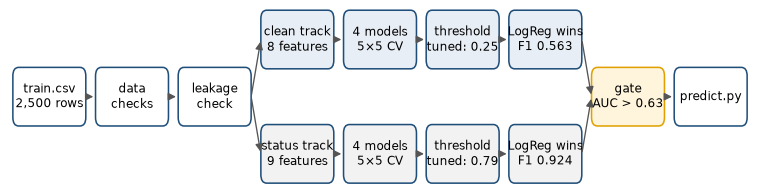

In [2]:
fig_workflow()

*Workflow. The clean track drops `status_code`; the status track keeps it. Both run the same 4 candidates on the same 25 folds, and the gate picks a track per scoring file.*

In [3]:
headline()

track,model shipped,F1 (nested),precision,recall,threshold
clean,LogReg,0.563,0.453,0.754,0.250
status,LogReg,0.924,0.929,0.920,0.790


expected hidden-file F1: 0.554 if status_code is blank or unrelated; 0.922 if it behaves as in training


* **Task and metric.** Predict `placed` for new students, scored by F1 (balance of precision and recall). Precision (share of flagged students who are placed) and recall (share of placed students we flag) come from OOF predictions (made by a model that never saw the row) at the chosen threshold (probability cut-off for saying placed).
* **Key decision.** `status_code` looks like leakage (a field that reveals the answer). The default is the clean model; a gate switches to the status model only when the scoring file shows the training pattern.
* **Expected hidden-file F1.** 0.554 if `status_code` is blank, stale or unrelated; 0.922 if it behaves as in training.

## 2. Dataset: 2,500 students, 9 candidate features, 28.1% placed

In [4]:
show(dataset_table()); class_balance()

column,type,meaning (README),range or categories,missing,used in model
student_id,text,Student id,S00001 to S02500,0.0%,no (identifier)
department,categorical,Branch,"CSE, IT, ECE, EEE, MECH, CIVIL",0.0%,yes
city_tier,integer,"1, 2, or 3",1 to 3,0.0%,yes
cgpa,continuous,Cumulative GPA,5.0 to 10.0,4.7%,yes
backlogs,integer,Active backlogs,0 to 6,6.7%,yes
internship_months,integer,"Length of internship, in months",0 to 6,0.0%,yes
coding_score,continuous,"Internal coding test, out of 100",5.2 to 100.0,21.0%,yes
projects,integer,Number of projects listed,0 to 10,0.0%,yes
workshops,integer,Number of workshops attended,0 to 4,0.0%,yes
status_code,binary,A field stored on the placement portal,0 to 1,4.5%,status track only


class balance: 702 of 2,500 placed (28.1%)  ███████████░░░░░░░░░░░░░░░░░░░░░░░░░░░░░


* `student_id` is dropped (identifier); `status_code` is used only in the status track; every other column feeds both tracks.

## 3. EDA: cgpa, coding_score and department carry the signal; the data is clean

### cgpa, coding_score and department separate the classes most; city_tier and workshops barely do

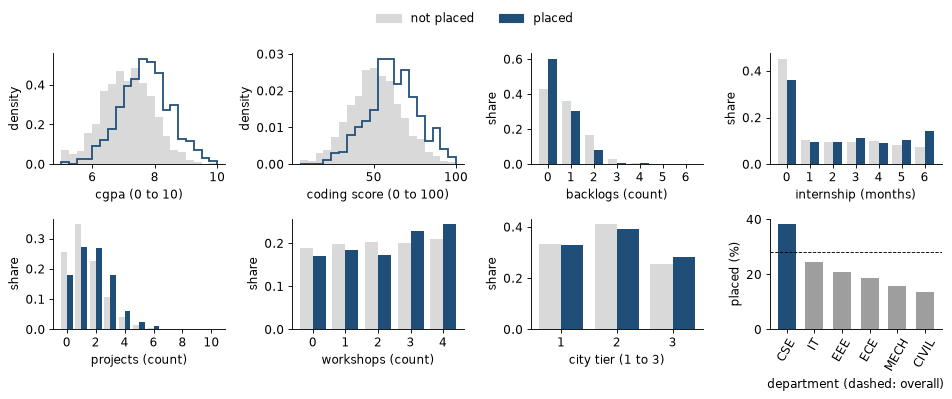

placement rate by department: CSE 38.4% (n=1,074), IT 24.5% (n=535), EEE 20.8% (n=269), ECE 18.7% (n=273), MECH 15.8% (n=209), CIVIL 13.6% (n=140)


In [5]:
fig_distributions()

*Numeric features by outcome (densities for continuous, share within each outcome for counts). Last panel: department is the clearest categorical signal, 38.4% placed in CSE vs 13.6% in CIVIL.*

### Only a missing cgpa is informative

In [6]:
show(missing_table())

column,missing,missing %,placed if missing,placed if present
cgpa,118,4.7%,34.7%,27.7%
backlogs,168,6.7%,29.8%,28.0%
coding_score,525,21.0%,27.4%,28.3%
status_code,113,4.5%,21.2%,28.4%


* **What we see.** 34.7% are placed when cgpa is missing vs 27.7% when present; the other gaps are close to uninformative.
* **What we did.** Median imputation plus a `<col>_missing` indicator for every numeric column, even those with no gaps.
* **Why.** The hidden file can have empty cells in any column.

### One duplicate feature pair and no impossible values

In [7]:
show(quality_table())

check,result,decision
full-row duplicates,0,nothing to remove
feature-row duplicates,"2 rows (S02003 and S02454), same label",kept: one consistent pair cannot bias the model
duplicate student_id,0,ids are unique
id number vs placed,r = -0.012,"identifier with no signal, excluded"
values outside valid range,0,none to fix; predict.py still clips
cgpa exactly 5.0,14 students,looks like a floor; kept
department spellings,"CIVIL, CSE, ECE, EEE, IT, MECH",six clean values


* **Decision.** Nothing removed: all values lie in valid ranges, and 14 students at cgpa exactly 5.0 look like a floor, not an error.

## 4. `status_code` is almost a copy of the label

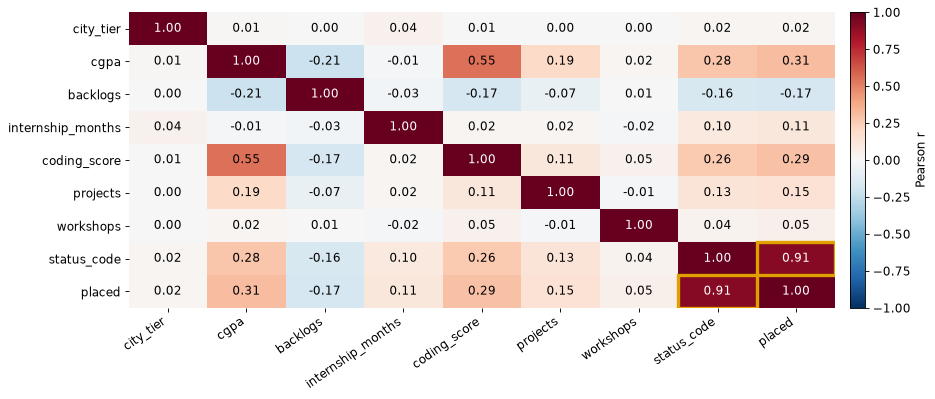

correlation with placed: status_code 0.910, cgpa 0.309, coding_score 0.292, backlogs -0.167, projects 0.147, internship_months 0.115, workshops 0.048, city_tier 0.020
status_code vs cgpa 0.276, vs coding_score 0.261


In [8]:
fig_correlation()

*Pearson correlation on pairwise complete rows. For 0/1 columns this equals point-biserial correlation. Gold boxes: `status_code` vs `placed`.*

In [9]:
show(status_crosstab())

status_code,students,placed,placement rate
1,700,645,92.1%
0,1687,33,2.0%
missing,113,24,21.2%


In [10]:
show(stress_table()); print(f"{runs.groupby('scenario').size().iloc[0]} simulated test files per scenario")

status_code in test file,without it,always with it,gated
intact,0.554,0.921,0.922
shuffled,0.554,0.294,0.554
half blank,0.554,0.664,0.719
blank,0.554,0.200,0.554


60 simulated test files per scenario


*Stress test: mean F1 over 60 simulated test files per scenario (Section 8), models refit on the remaining rows by train.py.*

* **What we see.** 92.1% of students with `status_code = 1` are placed vs 2.0% with `status_code = 0` (r = 0.910), yet it correlates only 0.276 with cgpa, so it is not a merit score.
* **Why it is probably post-outcome.** The README describes every column except this one, and the scoring file is a list of "new registered students" who should not hold offers yet. This is classic leakage (Kaufman et al., "Leakage in Data Mining", ACM TKDD 2012).
* **What we did.** Two tracks with identical candidates plus a gate. Always using `status_code` falls to 0.294 F1 when shuffled and 0.200 when blank, below the clean model (0.554).

## 5. Four model families, one validation protocol, selection rule fixed in advance

In [11]:
show(methods_table()); print(f"protocol: {pl.N_SPLITS}x{pl.N_REPEATS} repeated stratified CV = {NFOLDS} folds, seed {pl.SEED}; rule: beat LogReg by >= {SEL_MARGIN} F1 and win >= {SEL_WINS} of {NFOLDS} folds")

model,why it is in the comparison,reference
Logistic Regression (elastic-net),"Strong, interpretable baseline for small tabular data; coefficients explain predictions","Hastie, Tibshirani & Friedman, Elements of Statistical Learning"
XGBoost,Gradient-boosted trees: the standard strong model for tabular data; handles missing values natively,"Chen & Guestrin, KDD 2016"
LightGBM,"Same family, faster, different tree growth; checks whether boosting helps","Ke et al., NeurIPS 2017"
Blend (LogReg + best booster),Averaging different model types can reduce error (best booster: LightGBM in both tracks),standard ensembling


protocol: 5x5 repeated stratified CV = 25 folds, seed 42; rule: beat LogReg by >= 0.01 F1 and win >= 15 of 25 folds


* **No deep learning.** On small tabular data tree models and linear models usually beat neural nets (Grinsztajn et al., NeurIPS 2022; Shwartz-Ziv & Armon, Information Fusion 2022).
* **Validation.** Repeated 5×5 stratified CV with the same splits for every model; the threshold is chosen inside the CV (nested CV: threshold picked on other folds), so the reported F1 is not optimistic.
* **Selection rule, stated before the results.** A complex model must beat LogReg by ≥ 0.01 F1 and win ≥ 15 of 25 folds. Other candidates are in the Appendix.

## 6. Logistic regression wins both tracks; the threshold matters more than the model

In [12]:
results()

track,model,nested F1,precision,recall,PR-AUC,ROC-AUC,threshold,folds won
clean,LogReg,0.563 ± 0.029,0.453,0.754,0.570,0.766,0.250,reference
clean,LightGBM,0.552 ± 0.024,0.446,0.745,0.558,0.755,0.255,5 of 25
clean,XGBoost,0.549 ± 0.029,0.451,0.748,0.562,0.758,0.255,8 of 25
clean,Blend LR+LGBM,0.562 ± 0.028,0.467,0.726,0.568,0.763,0.270,10 of 25
status,LogReg,0.924 ± 0.016,0.929,0.920,0.944,0.975,0.790,reference
status,LightGBM,0.920 ± 0.013,0.927,0.919,0.938,0.973,0.555,5 of 25
status,XGBoost,0.918 ± 0.014,0.932,0.915,0.940,0.974,0.635,4 of 25
status,Blend LR+LGBM,0.922 ± 0.014,0.931,0.916,0.943,0.975,0.725,8 of 25


max folds won vs LogReg: clean 10, status 8 of 25; tuned booster max_depth: 2 to 3


*Nested F1: mean ± std over 25 folds. Precision and recall: OOF predictions at each model's threshold. PR-AUC (area under precision-recall curve) is more informative than ROC-AUC when only 28.1% are positive.*

clean : of 1,168 flagged, 529 are placed (45.3%); found 529 of 702 placed students (75.4%)
status: of 695 flagged, 646 are placed (92.9%); found 646 of 702 placed students (92.0%)


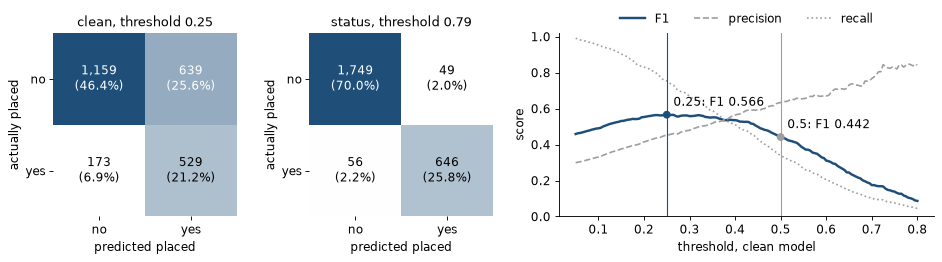

F1 at 0.5 = 0.442; at 0.25 = 0.566; best F1 / 2 = 0.283 (theory: optimal threshold is about half the best F1)


In [13]:
fig_results()

*Left: confusion matrices of the shipped models (OOF predictions, counts and share of all 2,500 students). Right: F1, precision and recall vs threshold for the clean model. Sanity check (Lipton, Elkan & Narayanaswamy 2014): the optimal threshold should be near best F1 / 2 = 0.283; the chosen 0.25 is close.*

* **LogReg won both tracks.** No alternative wins more than 10 of 25 folds (clean) or 8 of 25 (status). The tuned boosters chose depth 2 to 3 trees: there is little non-linearity to find.
* **The threshold is the biggest gain.** Moving from the default 0.5 to 0.25 lifts clean F1 from 0.442 to 0.566.
* **In placement terms.** Of students the clean model flags as likely placed, 45.3% are; it finds 75.4% of those who get placed. The status model: 92.9% and 92.0%.

## 7. Explainable AI: department, cgpa and coding_score drive the clean model

### Odds ratios: CSE and cgpa raise the odds most; backlogs lower them

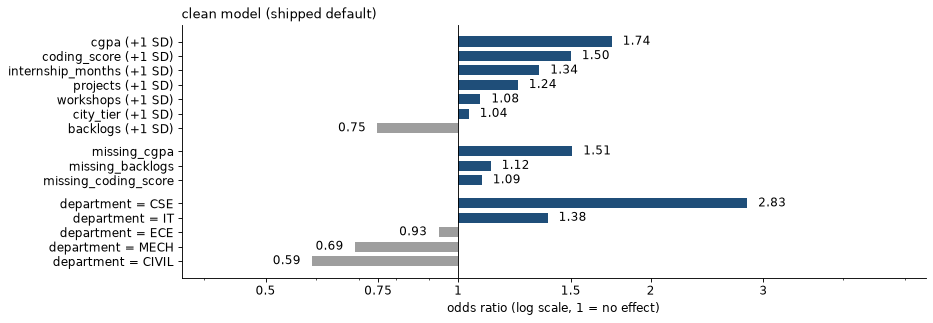

odds ratios: department = CSE 2.83, cgpa 1.74, coding_score 1.50, backlogs 0.75, missing_cgpa 1.51; 5 coefficients are exactly zero


In [14]:
fig_odds()

*Odds ratio (multiplier on odds of placement) = exp(coefficient) on standardised features: 1.5 means each +1 standard deviation multiplies the odds of placement by 1.5. Groups: numeric features, `missing_<feature>` indicators, department. Zero coefficients are omitted.*

### SHAP and permutation importance give the same ranking

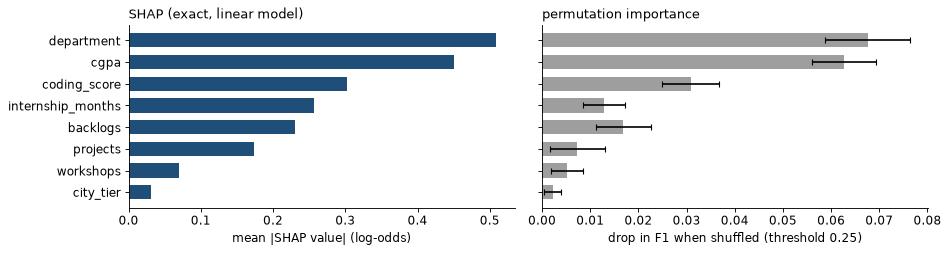

SHAP ranking:        department 0.509, cgpa 0.450, coding_score 0.303, internship_months 0.257, backlogs 0.231, projects 0.174, workshops 0.069, city_tier 0.031
permutation ranking: department, cgpa, coding_score, backlogs, internship_months, projects, workshops, city_tier


In [15]:
fig_importance()

*SHAP (each feature's share of one prediction) for a linear model is exact: coef × (x − mean) on the transformed features (Lundberg & Lee, NeurIPS 2017); one-hot and missing columns are summed into their source feature. Permutation: drop in F1 at the chosen threshold when one column is shuffled, 10 repeats, shipped model on the training rows (no refit).*

### Higher cgpa and coding_score push predictions up; more backlogs push them down

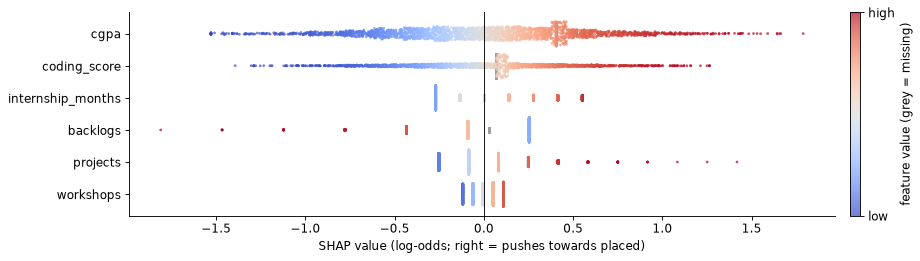

In [16]:
fig_beeswarm()

*One dot per student. Department is categorical and shown in the odds-ratio chart instead.*

### Two students explained

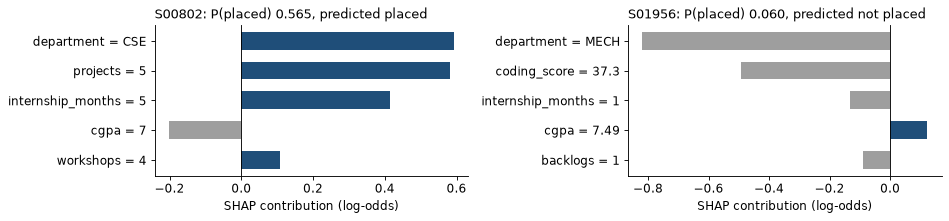

student,P(placed),prediction,actual,plain-English reading (top 3)
S00802,0.565,placed,placed,"Pushed up by department = CSE, projects = 5, internship_months = 5."
S01956,0.060,not placed,not placed,"Pushed down by department = MECH, coding_score = 37.3, internship_months = 1."


average student (all features at their mean): P(placed) 0.232


In [17]:
fig_local()

*Top 5 SHAP contributions of the first student in the file predicted placed and the first predicted not placed.*

### Status track: `status_code` outweighs every student feature

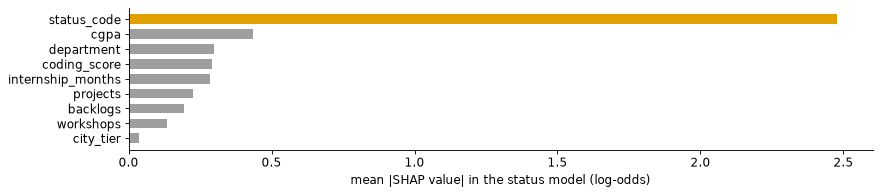

status model mean |SHAP|: status_code 2.478, next cgpa 0.434 (5.7x)


In [18]:
fig_status()

*Status model, mean |SHAP| per source feature; `status_code` includes its missing indicator.*

* **Top drivers.** department, cgpa, coding_score, then internship_months and backlogs by SHAP (permutation swaps the last two).
* **Weak features.** city_tier and workshops add little; they are kept because elastic-net (L1 plus L2 penalty) already shrinks them, and 5 coefficients are exactly zero.
* **Methods agree.** SHAP and permutation importance share the same top three. These explain the model, not causes.

## 8. The gate uses `status_code` only when the scoring file behaves like training

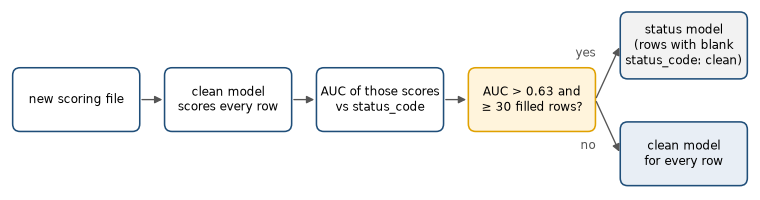

In [19]:
fig_gate()

*Gate logic in predict.py (`placement_lib.score_frame`).*

In [20]:
gate_summary()

scenario,status chosen,gated F1,clean only F1,always status F1
intact,100% / 100% / 100%,0.926 / 0.916 / 0.924,0.552 / 0.547 / 0.564,0.921 / 0.918 / 0.925
shuffled,0% / 0% / 0%,0.552 / 0.547 / 0.564,0.552 / 0.547 / 0.564,0.308 / 0.278 / 0.297
blank,0% / 0% / 0%,0.552 / 0.547 / 0.564,0.552 / 0.547 / 0.564,0.156 / 0.219 / 0.226
half blank,95% / 100% / 100%,0.722 / 0.715 / 0.722,0.552 / 0.547 / 0.564,0.689 / 0.645 / 0.659


safe = status chosen in >= 95% of intact files (>= 250 rows) and <= 5% of shuffled or blank ones (rule in train.py)
gate threshold 0.63: safe range 0.56 to 0.70, mean gated F1 0.687; status chosen in 100% of intact and 0% of shuffled or blank files
train.csv: gate AUC 0.747 -> status; shuffled copy: 0.500 -> clean
at 100 rows: intact AUC min 0.637, shuffled AUC max 0.623


*Each cell: test files of 100 / 250 / 500 rows, 20 stratified files per size; models refit on the remaining rows by train.py.*

* **Gate threshold 0.63.** Thresholds from 0.56 to 0.70 pick status in ≥ 95% of intact files (≥ 250 rows) and ≤ 5% of shuffled or blank ones; 0.63 sits in the middle and has the highest mean gated F1 (0.687).
* **Weak spot at about 100 rows.** Intact files reached an AUC as low as 0.637 and shuffled files as high as 0.623, so the margin is thin.
* **Blind spot.** A legitimate pre-offer field that tracks merit would also pass. In production, ask the placement cell when `status_code` is written.

## 9. Robustness, limitations, future scope, scaling

### Blank cells cost the clean model 0.033 F1 at 20%

In [21]:
show(robustness_table())

track,0% blank,10% blank,20% blank,drop at 20%
clean,0.563,0.549,0.530,0.033
status,0.922,0.876,0.830,0.093


*Random share of all feature cells blanked in each held-out fold. Status-track rows with a blank `status_code` fall back to the clean model.*

### Limitations

In [22]:
show(limitations_table())

limitation,impact,mitigation
"small data (2,500 rows)",fold-to-fold F1 std 0.029; gaps below 0.01 are noise,"repeated CV, paired folds, prefer the simpler model"
status_code meaning unconfirmed,expected F1 is 0.554 or 0.922 depending on the field,validity gate; ask the placement cell
F1 ceiling with available features,clean F1 about 0.56; boosted models add nothing,new information about students
modest precision at the chosen threshold,precision 0.453: many false positives,raise the threshold if precision matters more
gate noisy on small files,"at 100 rows intact AUC fell to 0.637, shuffled rose to 0.623",minimum-row guard; manual review of small batches
drift between batches,a different placement rate moves the best threshold,monitor predicted positive rate; re-tune per batch
correlation is not causation in XAI,"coefficients and SHAP describe the model, not causes",no interventions based on them alone


### Future scope

In [23]:
show(future_table())

idea,expected benefit
confirm when status_code is written,removes the main uncertainty and the need for the gate
"more features: aptitude test, company tier, communication score, attendance",raises the F1 ceiling of the clean model
calibration monitoring and threshold re-tuning per batch,keeps the threshold F1-optimal when the placement rate changes
fairness check by department and city_tier,compares error rates across groups before real use
"monotonic constraints in boosting (cgpa up, backlogs down)",non-linear effects with sensible directions
collect more batches and years,lower variance; a fair test of more flexible models


### Scaling

In [24]:
show(scaling_table())

concern,approach
bigger data,same sklearn pipeline scales linearly; LogReg trains in seconds on millions of rows; or switch to SGD or LightGBM
batch scoring,predict.py is stateless: run it per batch or behind a FastAPI endpoint
model registry and versioning,"model bundle, thresholds and gate settings registered together (MLflow)"
monitoring,"input drift, gate AUC per batch, predicted positive rate, F1 once outcomes arrive"
retraining,scheduled retraining per placement season with the same validation protocol
reproducibility,"pinned requirements, fixed seeds, saved CV reports"


## Appendix: other candidates tried; none beat logistic regression

In [25]:
show(appendix_table(), collapsed="Other candidates and feature checks (click to expand)")

track,variant,details,nested F1,change vs LogReg
clean,Blend: LR + XGBoost,"rank-average, equal weights",0.556 ± 0.032,-0.007
clean,Blend: LR + LightGBM + XGBoost,"mean, LR weight 0.50",0.558 ± 0.033,-0.005
clean,Stacking (LR meta-model),"LR on OOF probabilities of LR, LightGBM, XGBoost",0.555 ± 0.032,-0.008
clean,LR + engineered features,"cgpa × coding_score, has_internship, has_backlog",0.559,-0.004
clean,"LR, city_tier one-hot",same hyperparameters as the selected LR,0.559,-0.004
status,Blend: LR + XGBoost,"mean, LR weight 0.70",0.923 ± 0.015,-0.001
status,Blend: LR + LightGBM + XGBoost,"rank-average, equal weights",0.921 ± 0.015,-0.003
status,Stacking (LR meta-model),"LR on OOF probabilities of LR, LightGBM, XGBoost",0.921 ± 0.014,-0.003
status,LR + engineered features,"cgpa × coding_score, has_internship, has_backlog",0.923,-0.002
status,"LR, city_tier one-hot",same hyperparameters as the selected LR,0.922,-0.002
